## Semiconductor Lab B7 - Task 5

Measure the mode spectrum at an operating current above the threshold. Determine the
effective refractive index of the active material from the mode separation and the
length of the resonator, which has been determined by means of a light microscope
before. The dispersion shall be neglected: $(d\bar{n}/d\lambda) \to 0$.

In [14]:
%matplotlib inline

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

from b7.python.config import DATA_DIR, PLOTS_DIR, SINGLE_COLUMN
from b7.python.helper import read_spectrum

In [15]:
data_dir: Path = DATA_DIR / "task_5"
export_dir: Path = PLOTS_DIR

### Import Data

In [16]:
df_19mA: pd.DataFrame = read_spectrum(data_dir / "19mA.txt")

### Enrich Data

In [17]:
peaks, _ = find_peaks(df_19mA["signal"], prominence=0.002)
lambda_peaks: np.ndarray = df_19mA["lambda_nm"].to_numpy()[peaks]
signal_peaks: np.ndarray = df_19mA["signal"].to_numpy()[peaks]

d_lambda: np.ndarray = np.diff(lambda_peaks)
d_lambda_mean: float = d_lambda.mean()
d_lambda_sem: float = d_lambda.std(ddof=1) / np.sqrt(len(d_lambda))
lambda_mean: float = lambda_peaks.mean()

pprint({
    "n_peaks": len(lambda_peaks),
    "d_lambda_mean_nm": d_lambda_mean,
    "d_lambda_sem_nm": d_lambda_sem,
    "lambda_mean_nm": lambda_mean,
})

{'d_lambda_mean_nm': np.float64(0.25),
 'd_lambda_sem_nm': np.float64(0.005270462766966472),
 'lambda_mean_nm': np.float64(776.4454545454545),
 'n_peaks': 11}


### Effective Refractive Index

With dispersion neglected ($d\bar{n}/d\lambda \to 0$, as the task specifies), the mode
spacing and cavity length give the effective index directly,

$$ \bar{n} = \frac{\lambda^2}{2 L \, \Delta\lambda}. $$

`L_NM` below is the cavity length

In [18]:
L_NM: float = 300_000.0  

n_eff: float = lambda_mean**2 / (2 * L_NM * d_lambda_mean)
n_eff_err: float = n_eff * (d_lambda_sem / d_lambda_mean)

pprint({"L_nm": L_NM, "n_eff": n_eff, "n_eff_err": n_eff_err})

{'L_nm': 300000.0,
 'n_eff': np.float64(4.019116959228649),
 'n_eff_err': np.float64(0.0847304251587924)}


### Plot Data

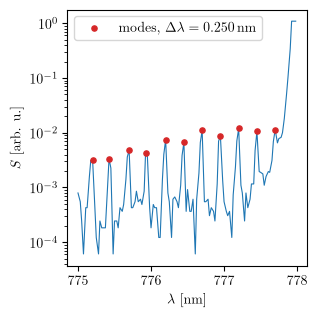

In [19]:
with plt.rc_context(SINGLE_COLUMN):
    fig, ax = plt.subplots(layout="constrained")

    ax.plot(df_19mA["lambda_nm"], df_19mA["signal"], color="tab:blue", linewidth=0.8)
    ax.scatter(
        lambda_peaks,
        signal_peaks,
        color="tab:red",
        s=14,
        zorder=3,
        label=rf"modes, $\Delta\lambda = \qty{{{d_lambda_mean:.3f}}}{{\nano\meter}}$",
    )
    ax.set_yscale("log")
    ax.set_xlabel(r"$\lambda$ [\unit{\nano\meter}]")
    ax.set_ylabel(r"$S$ [arb. u.]")
    ax.legend()

    fig.savefig(export_dir / "task5.pdf")
    plt.show()

### Result

|        | $\Delta\lambda$       | $n$ peaks | $L$ (placeholder) | $\bar{n}$       |
|--------|------------------------|-----------|--------------------|------------------|
| `19mA` | $(0.250 \pm 0.005)$ nm | 11        | 300 µm             | $4.02 \pm 0.08$  |

- The spectrum  features a series of equidistant peaks 
- notes are spaced equally with 0.250+-005nm
- mode at 777.95 saturates lock-in , peak could not be located exactly 
- With a cavity length of 300 mu m, this results in an effective refractive index of 4.0+-0.1
